### 本册学什么（导读）
这本笔记本演示**拉曼光谱预处理**的完整流程。拉曼光谱记录"散射光频率变化 vs 光强"，能反映分子的振动"指纹"；但仪器测得的原始曲线通常带有**噪声（毛刺）**和**基线漂移（背景整体倾斜/隆起）**，直接分析会失真。
我们将依次完成：① 导入数据 → ② 向量化并画出原始光谱 → ③ 平滑去噪（窗口移动平均 / Savitzky–Golay / 惩罚最小二乘 三法对比）→ ④ 基线校正（I-ModPoly / airPLS / MPLS 三法对比）→ ⑤ 峰检测（find_peaks / 连续小波 两法对比）。
每一步先用通俗语言讲原理，再用代码实现，并把处理前后的光谱画在同一张图里对比。读完你应该能说出每一步"为什么做"，以及处理后图上应该看到什么变化。

# 步骤1：导入该实验所需的通用包
FROM 《第9章 人工智能辅助的化学计量学实验-教材》（实验9-2  拉曼光谱的表示与预处理）  
使用到的通用包有：***NumPy***、***Matplotlib*** 

In [11]:
# 导入 numpy 数值计算库（习惯简写 np），后面用它处理数组/向量
import numpy as np
# 导入 matplotlib 的 pyplot 画图模块（习惯简写 plt），用来绘制光谱图
import matplotlib.pyplot as plt
# 设置画图中文字体为宋体，否则图里的中文会显示成方框
plt.rcParams['font.sans-serif'] = ['SimSun'] # 用来正常显示中文标签

# 步骤2：导入原始数据，对其进行向量表示

### 2.1 导入原始数据
原始数据的存储格式为.csv文件，第一列指的是拉曼位移，每二列指的是拉曼强度。  

            



In [12]:
# 导入 pandas 表格数据处理库（习惯简写 pd）
import pandas as pd
# path 存数据文件的路径；字符串前的 r 表示"原始字符串"，防止 \ 被当成转义符（Windows 路径要这样写）
path=r"E:\JS\785nm-1200G\WS-23-实际-8-0.txt"  #原始数据存储格式为.csv文件
# read_csv() 读取数据：delimiter='\t' 表示列之间用制表符分隔；header=None 表示文件没有表头行
# skiprows=43 跳过开头 43 行仪器参数说明；encoding 指定文字编码
data = pd.read_csv(path, delimiter='\t', header=None, skiprows=43, encoding='ISO-8859-1')  #读取数据
# print() 打印读到的表格，检查读取是否正确
print(data)

             0         1
0      200.052  148.1030
1      201.312  147.8970
2      202.571  154.0340
3      203.830  152.0340
4      205.088  149.6900
...        ...       ...
1525  1796.000   90.3103
1526  1796.880   88.7931
1527  1797.750   88.2414
1528  1798.620   86.8621
1529  1799.490   88.5172

[1530 rows x 2 columns]


## 2.2 拉曼光谱数据的向量表示及可视化
首先将数据转换为array数组形式，再分别取出以向量的形式表示的拉曼位移数据（光谱图的横轴）和其对应的拉曼强度数据（光谱图的纵轴）。

In [193]:
# np.array() 把 pandas 表格转成 numpy 数组；data.T 是"转置"（行列互换），转完后第 0 行是拉曼位移、第 1 行是拉曼强度
data_array=np.array(data.T) #将数据转换为数组
print(data_array)
# 数组下标从 0 开始：取第 0 行作为 x 轴（拉曼位移）
x=data_array[0] #x轴数据表示拉曼位移，可表示成向量数据
print(x)
# .shape 显示向量的长度（元素个数）
print(x.shape)
# 取第 1 行作为 y 轴（拉曼强度）
y=data_array[1] #y轴数据表示拉曼强度，可表示成向量数据
print(y)
print(y.shape)

[[ 200.052   201.312   202.571  ... 1797.75   1798.62   1799.49  ]
 [ 148.103   147.897   154.034  ...   88.2414   86.8621   88.5172]]
[ 200.052  201.312  202.571 ... 1797.75  1798.62  1799.49 ]
(1530,)
[148.103  147.897  154.034  ...  88.2414  86.8621  88.5172]
(1530,)


## 2.3 根据x轴和y轴数据，绘制原始拉曼光谱图。

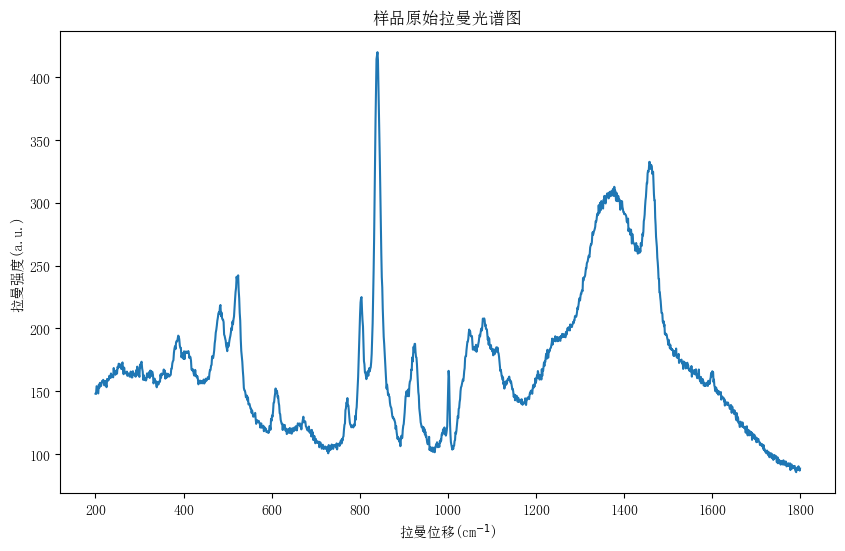

In [14]:
# 新建一张宽 10、高 6 英寸的画布
plt.figure(figsize=(10,6))
# plot(x, y) 以 x 为横轴、y 为纵轴画折线图——这就是光谱曲线
plt.plot(x,y)
# 设置横轴、纵轴的文字标签
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
# 设置图标题
plt.title('样品原始拉曼光谱图')
# show() 把图显示出来
plt.show()

#### 从样品原始拉曼光谱图可看出存在噪声、基线漂移，需要进行平滑去噪、基线校正。

# 步骤3：平滑去噪
### 3.1 窗口移动平均法


### 为什么要平滑去噪？
光谱上细小的"毛刺"来自仪器和环境的随机噪声。平滑去噪相当于给曲线"磨皮"：让毛刺消失，同时尽量不改变峰的位置、高度和形状。
本节对比三种方法：**窗口移动平均**（每个点取相邻几个点的平均值，简单但容易把峰"削矮"）、**Savitzky–Golay 窗口移动多项式**（在窗口内用多项式拟合，保峰效果更好）、**Whittaker 惩罚最小二乘**（在"贴近原始数据"和"曲线光滑"之间寻找最佳平衡）。
观察输出图：平滑后的曲线应明显比原始曲线光滑，而峰的位置基本不变。

原始拉曼光谱数据: [148.103  147.897  154.034  ...  88.2414  86.8621  88.5172]
移动平均结果: [ 74.0515  148.      150.9655  ...  88.51725  87.55175  87.68965]


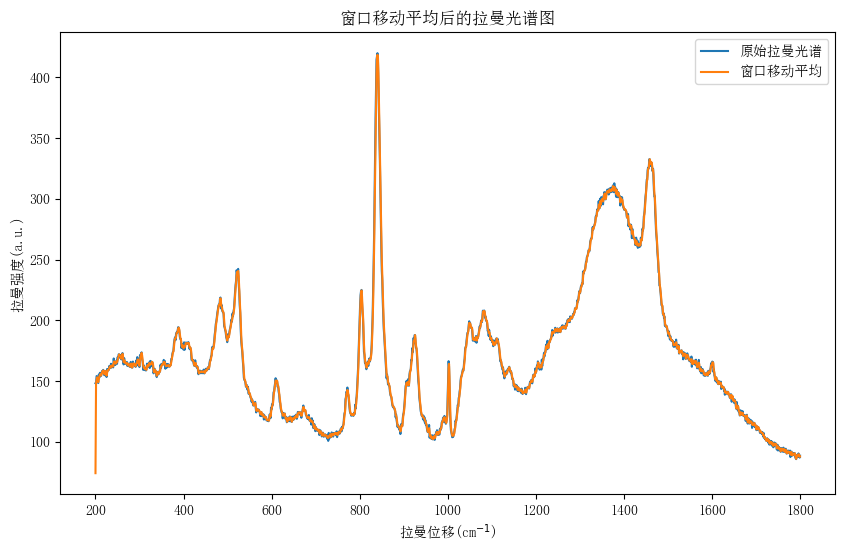

In [15]:
# 导入 scipy.signal 里的 convolve（卷积）函数
from scipy.signal import convolve
# 定义窗口大小
window_size = 5

# 创建一个窗口数组，这里使用窗口大小为window_size的全1数组
# np.ones(5) 生成 [1,1,1,1,1]，除以 5 得 [0.2,0.2,0.2,0.2,0.2]，五个数相加恰好等于 1（平均的保证）
window = np.ones(window_size) / window_size

# 使用convolve函数计算移动平均
# 卷积的效果：每个点被替换成"它自己和左右相邻共 5 个点的平均值"，毛刺就这样被抹平
moving_average_y = convolve(y, window, mode='same')

print("原始拉曼光谱数据:", y)
print("移动平均结果:", moving_average_y)
plt.figure(figsize=(10,6))
# label 参数给曲线取名，配合下面的 legend() 显示图例
plt.plot(x,y, label='原始拉曼光谱')
plt.plot(x,moving_average_y, label='窗口移动平均')
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('窗口移动平均后的拉曼光谱图')
# legend() 显示图例（左上角的小方框）
plt.legend()
plt.show()

### 3.2 窗口移动多项式法（Savitzky–Golay filter）

原始拉曼光谱数据: [148.103  147.897  154.034  ...  88.2414  86.8621  88.5172]
窗口移动多项式平滑后的数据: [147.78481429 149.16974286 152.12488571 ...  87.75667714  87.18524857
  88.43641286]


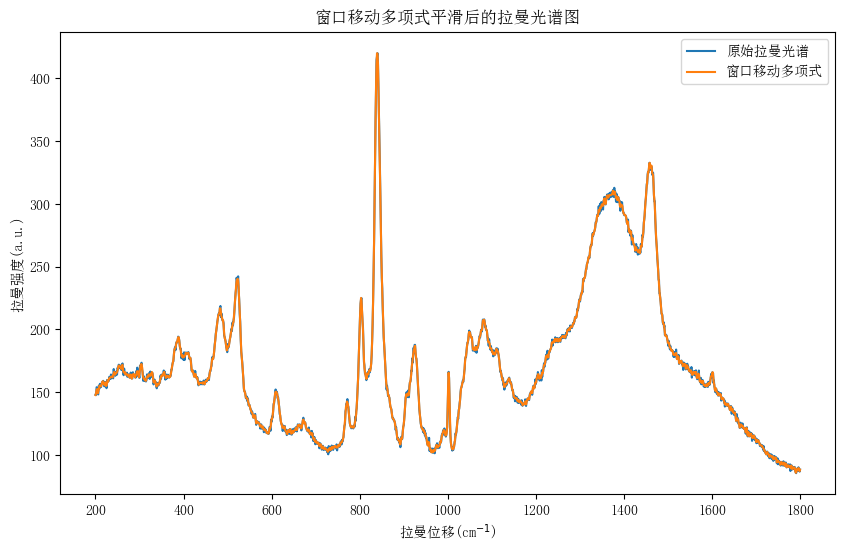

In [16]:
# 导入 Savitzky–Golay 平滑滤波函数
from scipy.signal import savgol_filter
# 定义窗口大小（必须是奇数）
window_size = 5

# 定义多项式的阶数
polyorder = 3

# 使用savgol_filter函数计算窗口移动多项式平滑
# 原理：在窗口内用一个三次多项式去拟合数据点，用拟合值代替原始值
# 优点：比移动平均更能保住峰的位置、高度和形状
sg_smoothed_y = savgol_filter(y, window_length=window_size, polyorder=polyorder)
print("原始拉曼光谱数据:", y)
print("窗口移动多项式平滑后的数据:", sg_smoothed_y)
plt.figure(figsize=(10,6))
plt.plot(x,y, label='原始拉曼光谱')
plt.plot(x,sg_smoothed_y, label='窗口移动多项式')
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('窗口移动多项式平滑后的拉曼光谱图')
plt.legend()
plt.show()

### 3.3 惩罚最小二乘法（维特克平滑法）
下面代码来源于[whittaker_smooth](https://github.com/mhvwerts/whittaker-eilers-smoother/blob/master/whittaker_smooth.py)。 此处为了方便使用，代码直接单元格形式，实际代码应单独写入至"whittaker_smooth.py"文件中。

In [17]:
# 本格重复导入 numpy，是为了让本格可以独立运行
import numpy as np
# scipy.sparse 处理"稀疏矩阵"（大部分元素是 0 的矩阵，省内存、速度快）
import scipy.sparse as sparse
# splu 是稀疏矩阵方程求解器（用 LU 分解解线性方程组）
from scipy.sparse.linalg import splu


def speyediff(N, d, format='csc'):
    """
    (utility function)
    Construct a d-th order sparse difference matrix based on
    an initial N x N identity matrix

    Final matrix (N-d) x N
    """
    # 上面英文说明：构造 d 阶"差分矩阵"，用来表示相邻数据点之间做 d 次相减的运算
    # assert 断言：条件不满足就立刻报错，这里保证阶数 d 不能为负
    assert not (d < 0), "d must be non negative"
    shape     = (N-d, N)
    diagonals = np.zeros(2*d + 1)
    diagonals[d] = 1.
    # for 循环：连续做 d 次"相邻两点相减"，得到 d 阶差分的系数
    for i in range(d):
        diff = diagonals[:-1] - diagonals[1:]
        diagonals = diff
    offsets = np.arange(d+1)
    # 把系数放到矩阵对角线上，生成稀疏差分矩阵
    spmat = sparse.diags(diagonals, offsets, shape, format=format)
    return spmat


def whittaker_smooth(y, lmbd, d = 2):
    """
    Implementation of the Whittaker smoothing algorithm,
    based on the work by Eilers [1].

    [1] P. H. C. Eilers, "A perfect smoother", Anal. Chem. 2003, (75), 3631-3636

    The larger 'lmbd', the smoother the data.
    For smoothing of a complete data series, sampled at equal intervals

    This implementation uses sparse matrices enabling high-speed processing
    of large input vectors

    ---------

    Arguments :

    y       : vector containing raw data
    lmbd    : parameter for the smoothing algorithm (roughness penalty)
    d       : order of the smoothing

    ---------

    Returns :

    z       : vector of the smoothed data.
    """
    # 上面英文说明：这是 Whittaker 平滑算法，lmbd 越大结果越平滑
    # m 是数据点的个数
    m = len(y)
    # E 是单位矩阵，代表"平滑结果要贴近原始数据"
    E = sparse.eye(m, format='csc')
    # D 是差分矩阵，代表"平滑结果要尽量不上下抖动"
    D = speyediff(m, d, format='csc')
    # 系数矩阵 = E + lmbd×DᵀD：把上面两个要求合成一个方程；lmbd 控制两者谁说了算
    coefmat = E + lmbd * D.conj().T.dot(D)
    # 解这个方程组，得到既贴近原数据又光滑的曲线 z
    z = splu(coefmat).solve(y)
    return z

原始拉曼光谱数据: [148.103  147.897  154.034  ...  88.2414  86.8621  88.5172]
惩罚最小二乘平滑后的数据: [149.19681916 149.74372875 151.2140027  ...  88.30326323  87.94911631
  88.13847754]


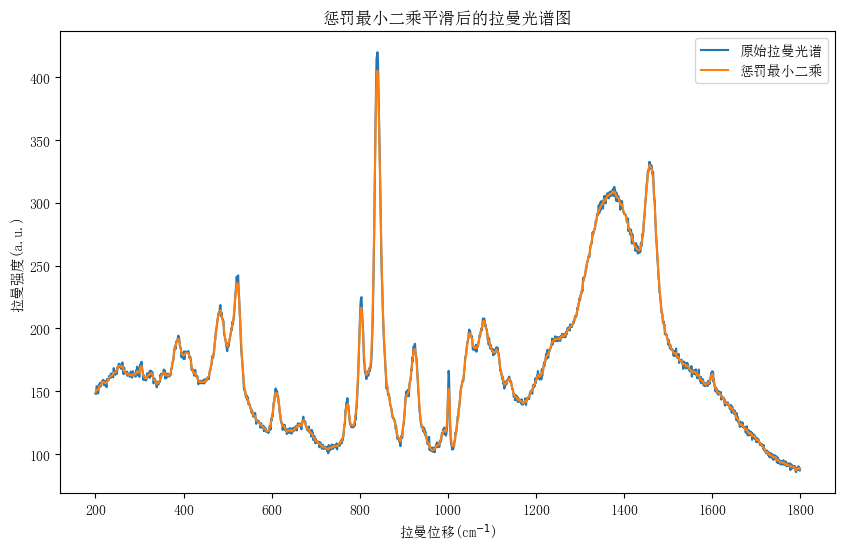

In [18]:
# from Whittaker_smoother import whittaker_smooth  # 从文件夹中的Whittaker_smoother.py文件导入自定义的Whittaker_smooth函数
# 调用上面定义的平滑函数：lmbd（惩罚系数）和 d（差分阶数）共同决定平滑强度，改这两个数可观察效果变化
whittaker_smooth_y = whittaker_smooth(y, lmbd=2, d=1) #lmbd代表惩罚项的系数，d代表差分的阶数，二者用于控制平滑的程度
print("原始拉曼光谱数据:", y)
print("惩罚最小二乘平滑后的数据:", whittaker_smooth_y)
plt.figure(figsize=(10,6))
plt.plot(x,y, label='原始拉曼光谱')
plt.plot(x,whittaker_smooth_y, label='惩罚最小二乘')
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('惩罚最小二乘平滑后的拉曼光谱图')
plt.legend()
plt.show()

**从三种方法的平滑结果图中来看，窗口移动多项式平滑对于该光谱的平滑效果最好。下面，我们基于窗口移动多项式平滑后的数据（sg_smoothed_y）进行基线校正。**


# 步骤4：基线校正
从pybaselines库导入Baselines模块，Baselines模块提供了多种基线校正算法，包含本实验涉及到的改进的修正多项式法（I-ModPoly）、自适应重加权惩罚最小二乘法（airPLS）、形态学加权惩罚最小二乘法（MPLS）这三种基线校正方法，运行这三种基线校正方法并在同一张图上可视化比较基线拟合效果。

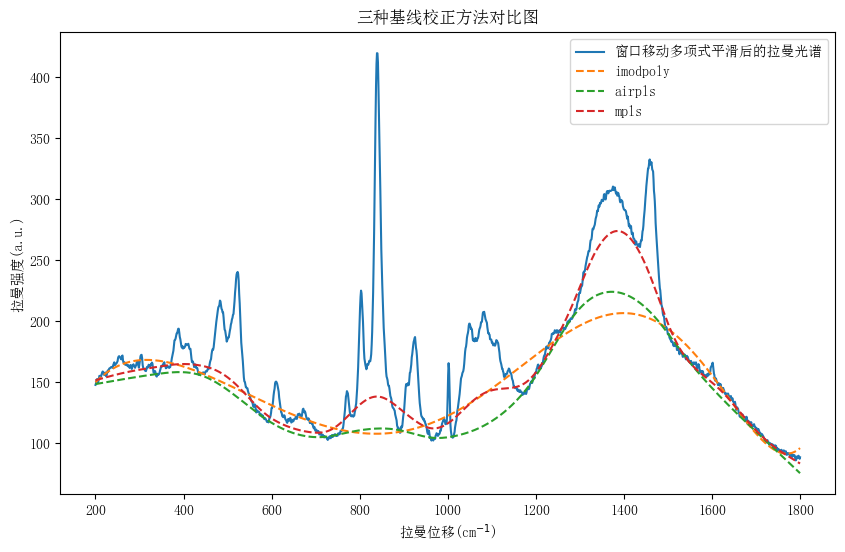

In [256]:
# 导入 pybaselines 库的 Baseline 模块：收录了大量现成的基线校正算法
from pybaselines import Baseline
# 创建基线拟合器，告诉它光谱的横轴（拉曼位移）数据
baseline_fitter = Baseline(x_data=x)
# 改进的修正多项式法
# imodpoly：反复用多项式拟合光谱，拟合时只保留基线附近的点，最后得到基线 bkg_1
bkg_1, params_1 = baseline_fitter.imodpoly(sg_smoothed_y, poly_order=7) #改进的修正多项式法
# 光谱减去基线 = 干净光谱（峰保留、背景归零），后面每种方法同理
imodpoly_y = sg_smoothed_y - bkg_1
# 自适应重加权惩罚最小二乘法
# airpls：把"不在峰上的点"认作基线点，反复加权拟合；lam=1e5（即 10 万）越大基线越平滑
bkg_2, params_2 = baseline_fitter.airpls(sg_smoothed_y, lam=1e5) #自适应加权惩罚最小二乘法
airpls_y = sg_smoothed_y - bkg_2
# 形态学加权惩罚最小二乘法
# mpls：先用"形态学运算"估计基线的大致形状，再用惩罚最小二乘细化；p 控制对噪声的容忍程度
bkg_3, params_3 = baseline_fitter.mpls(sg_smoothed_y, lam=1e5, p=0.01) #形态学加权惩罚最小二乘法
mpls_y = sg_smoothed_y - bkg_3
plt.figure(figsize=(10,6))
plt.plot(x, sg_smoothed_y, label='窗口移动多项式平滑后的拉曼光谱')
# '--' 表示用虚线画三条基线，便于和实线光谱区分
plt.plot(x, bkg_1, '--', label='imodpoly')
plt.plot(x, bkg_2, '--', label='airpls')
plt.plot(x, bkg_3, '--', label='mpls')
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('三种基线校正方法对比图')
plt.legend()
plt.show()

### 4.2 可视化经改进的修正多项式法基线校正后的拉曼光谱

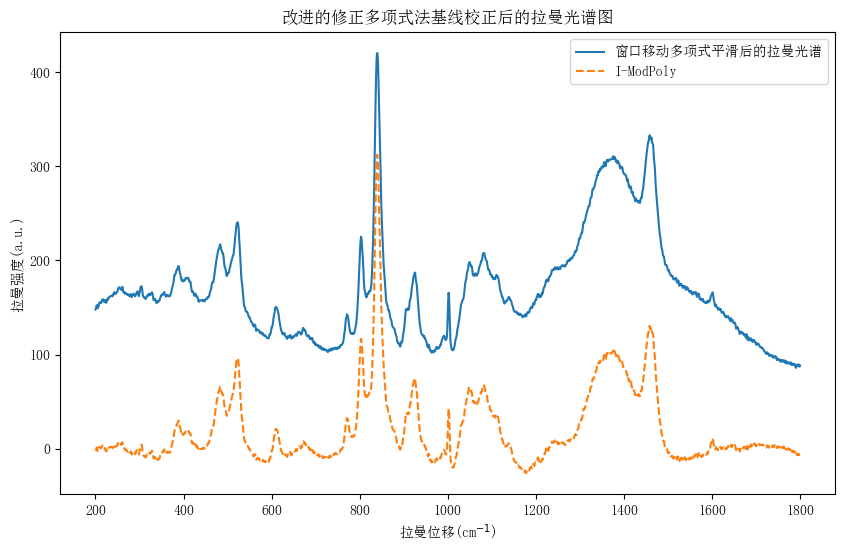

In [20]:
plt.figure(figsize=(10,6))
plt.plot(x, sg_smoothed_y, label='窗口移动多项式平滑后的拉曼光谱')
# 虚线是基线校正后的光谱：应更贴近横轴（背景被拉平到 0 附近，而峰基本不变）
plt.plot(x,imodpoly_y , '--', label='I-ModPoly')
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('改进的修正多项式法基线校正后的拉曼光谱图')
plt.legend()
plt.show()

### 4.3 可视化经自适应重加权惩罚最小二乘法基线校正后的拉曼光谱

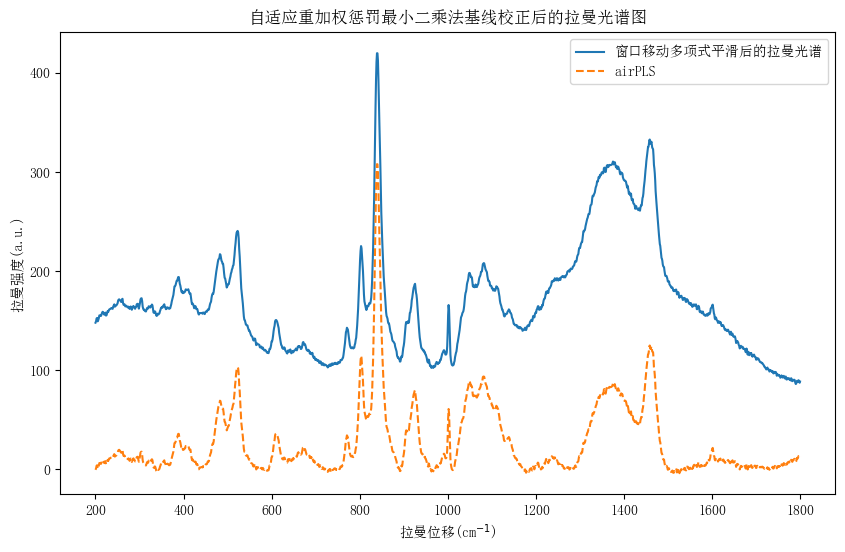

In [26]:
plt.figure(figsize=(10,6))
plt.plot(x, sg_smoothed_y, label='窗口移动多项式平滑后的拉曼光谱')
plt.plot(x,airpls_y , '--', label='airPLS')
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('自适应重加权惩罚最小二乘法基线校正后的拉曼光谱图')
plt.legend()

# os 是"操作系统"工具库，这里用来从完整路径中拆出文件名
import os
# 把数据文件名里的 txt 换成 png，拼出图片文件名（例如 bsWS-23-实际-8-0.png）
fig_name = "bs"+os.path.basename(path).replace('txt', 'png')
# savefig() 把当前这张图保存成图片文件
plt.savefig(fig_name)
plt.show()

### 4.4 可视化经形态学加权惩罚最小二乘法基线校正后的拉曼光谱

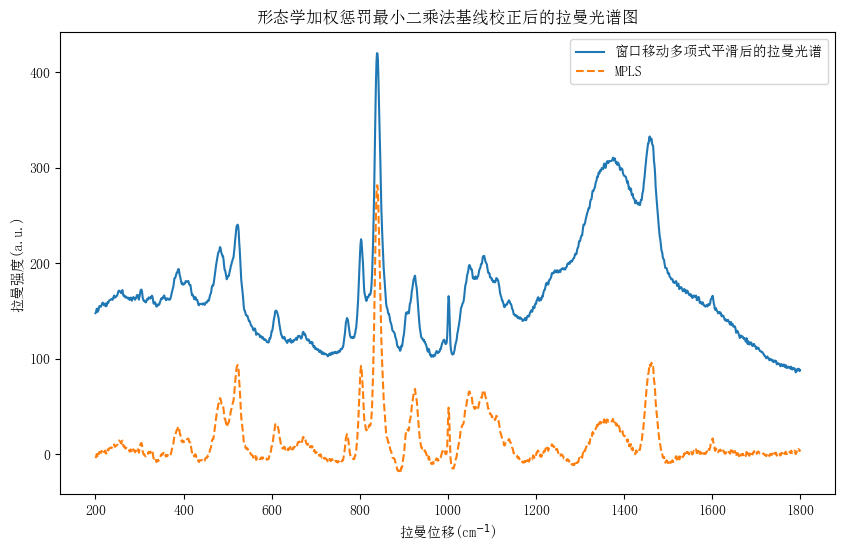

In [22]:
plt.figure(figsize=(10,6))
plt.plot(x, sg_smoothed_y, label='窗口移动多项式平滑后的拉曼光谱')
plt.plot(x,mpls_y, '--', label='MPLS')
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('形态学加权惩罚最小二乘法基线校正后的拉曼光谱图')
plt.legend()
plt.show()

**从上述三种方法的基线校正效果图可看出，自适应重加权惩罚最小二乘法取得了最好的效果。下面基于自适应重加权惩罚最小二乘法基线校正后的光谱数据（airpls_y）进行峰检测。**

# 步骤5： 峰检测

### 什么是峰检测？
拉曼光谱中的每个"峰"对应分子的一种振动模式，峰的**位置**（拉曼位移）是定性鉴别物质的"指纹"。峰检测就是让程序自动找出这些峰的准确位置。
本节对比两种方法：**find_peaks**（直接按峰高、突出度、峰宽等性质筛选峰顶）和**连续小波变换 find_peaks_cwt**（用不同宽度的"模板波形"去扫描曲线，宽峰窄峰都能捕捉）。
观察输出图：红色标记应落在真实峰顶上、不落在毛刺上；尝试修改筛选参数（如 prominence），可以看到检出峰数量的变化。

### 5.1 基于峰性质的检测方法（SciPy库中的find_peaks函数）

检测到的峰位置索引: [  49   84  103  153  231  265  340  394  482  511  544  624  696  741
  772  895  927 1070 1156 1308]
峰的性质: {'peak_heights': array([ 19.54776854,  17.56214005,   9.94280336,  35.57982176,
        69.02329803, 102.95376295,  35.93543632,  22.13665239,
        34.06606254, 114.39675315, 307.86449687,  79.648044  ,
        60.66732697,  88.90905202,  93.45080512,   6.55307316,
        12.98285831,  86.34932955, 124.78480344,  21.41170885]), 'prominences': array([ 15.90197264,  10.34965604,   6.29700746,  35.74103278,
        29.89043833,  81.88751933,  29.39031417,  15.59153024,
        21.99153761,  65.08057606, 295.78997193,  81.67659665,
        61.69063847,  16.65666551,  50.99452746,   6.93453122,
        13.92774804,  37.43885652,  79.7814899 ,  15.47470712]), 'left_bases': array([   0,   66,   92,  112,  191,  215,  322,  362,  443,  463,  495,
        592,  659,  705,  722,  868,  882, 1020, 1122, 1258], dtype=int64), 'right_bases': array([  92,  112,  112,  191,  244,

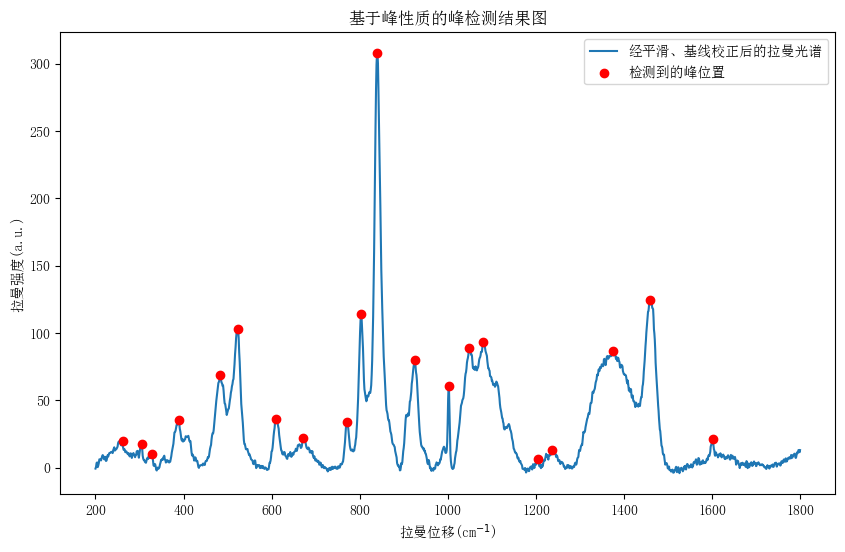

In [257]:
# 导入 find_peaks 峰检测函数
from scipy.signal import find_peaks
# np.where(条件) 返回满足条件的下标：这里筛出 600<拉曼位移<800 的区域（聚焦感兴趣的范围）
indices = np.where((x > 600) & (x < 800))[0]
# airpls_y = airpls_y[indices]
# find_peaks 按性质筛峰：height=0 峰要高于 0；distance=10 相邻峰至少隔 10 个点
# width=2 峰宽至少 2 个点；prominence=6 峰的"突出程度"至少 6（过滤小毛刺）；wlen=100 计算突出度时参考的窗口
peaks,properties = find_peaks(airpls_y,height=0,distance=10, width=2, prominence=6, rel_height=0.5, wlen=100)
print("检测到的峰位置索引:", peaks)
print("峰的性质:", properties)
plt.figure(figsize=(10,6))
plt.plot(x,airpls_y, label='经平滑、基线校正后的拉曼光谱')
# scatter 画散点：把找到的峰用红点标出；zorder=5 让点叠在曲线之上
plt.scatter(x[peaks], airpls_y[peaks], color='red', zorder=5, label='检测到的峰位置')
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('基于峰性质的峰检测结果图')
plt.legend()
plt.show()

检测到的峰位置索引: [  49   84  153  231  265  340  394  482  511  544  624  696  741  772
  927 1070 1156 1308]
峰的性质: {'peak_heights': array([0.07582355, 0.06945878, 0.12721303, 0.23441345, 0.34317487,
       0.12835293, 0.08412202, 0.1223608 , 0.37985447, 1.        ,
       0.26847023, 0.20762904, 0.29815566, 0.31271389, 0.05478025,
       0.28995067, 0.41315254, 0.08179827]), 'prominences': array([0.06488024, 0.033175  , 0.11456505, 0.09581143, 0.33677623,
       0.12058195, 0.04997742, 0.07049213, 0.20861063, 0.99586037,
       0.26180786, 0.19774446, 0.05339162, 0.30721088, 0.04464429,
       0.13253138, 0.41157424, 0.07176753]), 'left_bases': array([   0,   66,  112,  112,  112,  322,  362,  443,  443,  443,  592,
        659,  659,  659,  868,  868,  868, 1227], dtype=int64), 'right_bases': array([ 112,  112,  191,  244,  443,  443,  443,  495,  522, 1227,  659,
        705,  758,  868,  958, 1122, 1227, 1442], dtype=int64), 'widths': array([37.58381622,  4.58379413, 32.49835436, 13.2273

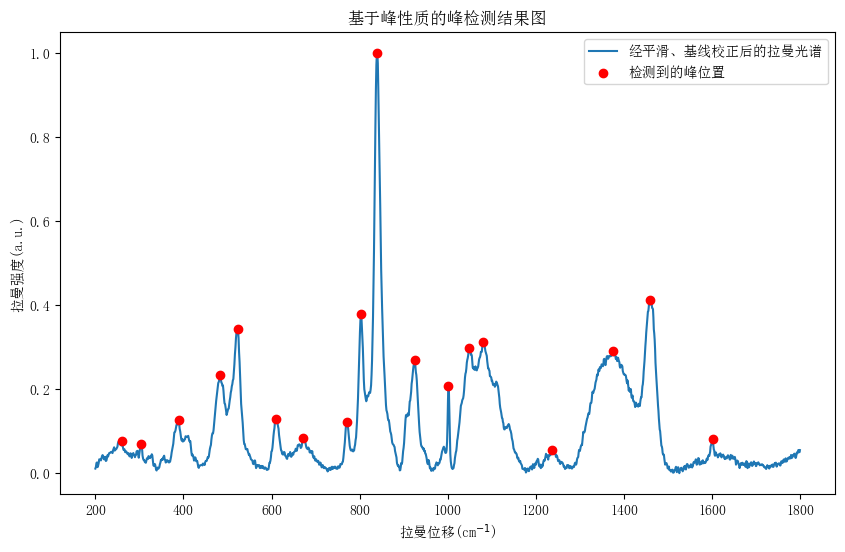

In [258]:
from scipy.signal import find_peaks
# 导入 minmax_scale 归一化工具：把数据线性缩放到 0~1 之间（最小值→0，最大值→1）
from sklearn.preprocessing import minmax_scale
# indices = np.where((x > 600) & (x < 800))[0]
# copy() 先复制一份数据再修改，不影响原来的 airpls_y
new_y = airpls_y.copy()
new_y = minmax_scale(new_y, feature_range=(0, 1), copy=False)

# 归一化后所有数值都在 0~1 之间，筛选阈值也要相应变小：height=0.050、prominence=0.02
peaks,properties = find_peaks(new_y,height=0.050,distance=10, width=2, prominence=0.02, rel_height=0.5)
print("检测到的峰位置索引:", peaks)
print("峰的性质:", properties)
plt.figure(figsize=(10,6))
plt.plot(x,new_y, label='经平滑、基线校正后的拉曼光谱')
plt.scatter(x[peaks], new_y[peaks], color='red', zorder=5, label='检测到的峰位置')
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('基于峰性质的峰检测结果图')
plt.legend()
plt.show()

峰面积可以使用RamPy包

### 5.2 连续小波变换方法(MassSpecWavelet)

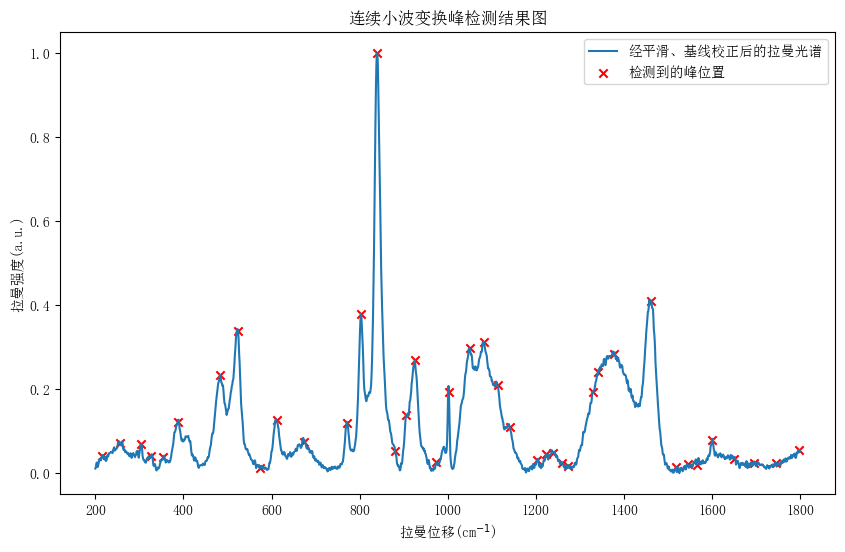

In [210]:
# 导入基于连续小波变换的峰检测函数
from scipy.signal import find_peaks_cwt
# widths表示尺度，是一个连续变化的参数
# np.arange(1,20) 生成 1~19 的整数序列：用不同"宽度"的小波模板去扫描，宽峰窄峰都能发现
cwt_widths=np.arange(1,20) # widths表示尺度，是一个连续变化的参数
# min_snr表示信噪比
# 信噪比阈值=1.0：低于该强度的"峰"当作噪声丢弃
min_snr=1.0 #min_snr表示信噪比
# 执行检测：gap_thresh=10 允许峰内部最多中断 10 个点；默认使用 Ricker（墨西哥帽）小波
peak_ind = find_peaks_cwt(airpls_y, cwt_widths, min_snr=min_snr, gap_thresh=10)#默认为Ricker波形
# 绘制峰检测结果图
# 这次用红色 × 号标出峰位置
plt.figure(figsize=(10,6))
plt.plot(x,airpls_y, label='经平滑、基线校正后的拉曼光谱')
plt.scatter(x[peak_ind],airpls_y[peak_ind],c='r', marker='x', label='检测到的峰位置')
plt.legend()
plt.xlabel('拉曼位移(cm$^{-1}$)')
plt.ylabel('拉曼强度(a.u.)')
plt.title('连续小波变换峰检测结果图')
plt.show()

**比较这二种方法的峰检测结果图，可看出对于该条拉曼光谱用SciPy中的find_peaks()方法检测峰值效果最好。**